In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# Connect and Access Git Repository

import sys
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())


GitHub token: ··········
Cloning into '/content/bachelor-thesis'...
remote: Enumerating objects: 739, done.
remote: Counting objects: 100% (254/254), done.
remote: Compressing objects: 100% (183/183), done.
remote: Total 739 (delta 164), reused 127 (delta 70), pack-reused 485 (from 2)
Receiving objects: 100% (739/739), 37.68 MiB | 21.84 MiB/s, done.
Resolving deltas: 100% (404/404), done.
/content/bachelor-thesis
Repo exists: True


In [3]:
# Imports
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import shap
from torch.utils.data import DataLoader



# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))


from utils.seed import set_seed, RANDOM_SEED
from models.tranad import TranADMainModel
from utils.dataset import PTBXLDataset
from explainability.shap_wrappers import TranADAnomalyScoreWrapper
from explainability.shap_utils import aggregate_shap_intervals, plot_normal_anomalous_shap_heatmaps
from explainability.visualization import plot_temporal_importance
from explainability.sample_selection import load_samples_from_dataset


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cuda


In [4]:
# Paths

DATA_DIR = Path("/content/drive/MyDrive/ECG data")
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"
EVALUATION_DIR = RESULTS_DIR / "evaluation"

MODEL_DIR = RESULTS_DIR / "models" / "tranad"

MODEL_PATH = MODEL_DIR / "tranad_20epochs_larger_capacity.pt"

SHAP_RESULTS_DIR = RESULTS_DIR / "shap"
SHAP_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

EXPLANATION_SAMPLES_PATH = RESULTS_DIR / "evaluation" / "visualization_samples.npz"


print("MODEL_PATH:", MODEL_PATH)
print("SHAP results:", SHAP_RESULTS_DIR)
print("Shared explanation samples:", EXPLANATION_SAMPLES_PATH)

MODEL_PATH: /content/drive/MyDrive/ECG data/results/models/tranad/tranad_20epochs_larger_capacity.pt
SHAP results: /content/drive/MyDrive/ECG data/results/shap
Shared explanation samples: /content/drive/MyDrive/ECG data/results/evaluation/visualization_samples.npz


In [5]:
# Load my preprocessed data

X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(17418, 1000, 12) (17418,)
(2198, 1000, 12) (2198,)


In [6]:
# Select normal data only

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

print("Training on normal ECGs:", X_train_normal.shape)

Training on normal ECGs: (7596, 1000, 12)


In [7]:
# Datasets

train_dataset = PTBXLDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

test_dataset = PTBXLDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [8]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [9]:
TranAD = TranADMainModel(
    NumFeatures=12,
    ModelDimension=64,
    NumHeads=4,
    NumEncoderLayers=2,
    NumDecoderLayers=2,
    ForwardDimension=128,
    DropoutRate=0.1,
    LearningRate=1e-4,
    FocusGrowthRate=1.05,
    InitialFocusScore=1.0,
    MaxFocusScore=5.0,
    AnomalyPercentile=95.0,
)

TranADModel: 268,376 Parameter | d_model=64, H=4, Enc=2, Dec×2=2


In [10]:
# Load the pre-trained model

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model checkpoint not found: {MODEL_PATH}"
    )

TranAD.Load(str(MODEL_PATH))
TranAD.Network.to(DEVICE)
TranAD.Network.eval()

print("TranAD checkpoint loaded.")

Model loaded  /content/drive/MyDrive/ECG data/results/models/tranad/tranad_20epochs_larger_capacity.pt
TranAD checkpoint loaded.


In [11]:
ScoreWrapper = TranADAnomalyScoreWrapper(TranAD)

In [12]:
background_indices = np.load(SHAP_RESULTS_DIR / "medium_background_indices.npy")

In [13]:
background_ECGs = torch.as_tensor(
    X_train[background_indices],
    dtype=torch.float32,
    device=DEVICE,
)

In [14]:
# select ECG samples to explain with SHAP
# I choose the same two samples used for Attention and SHAP on AnoFormer

VisualizationSamplePath = (
    EVALUATION_DIR
    / "visualization_samples.npz"
)

# Load shared samples for visualizations

VisualizationSamples = load_samples_from_dataset(
    sample_path=VisualizationSamplePath,
    test_dataset=test_dataset,
    device=TranAD.Device,
)


NormalSample = VisualizationSamples[0]
AnomalousSample = VisualizationSamples[1]

NormalIndex = NormalSample["index"]
AnomalousIndex = AnomalousSample["index"]

NormalECG = NormalSample["ecg"]
AnomalousECG = AnomalousSample["ecg"]

NormalLabel = NormalSample["label"]
AnomalousLabel = AnomalousSample["label"]


print("Visualization normal ECG:", NormalIndex, "Label:", NormalLabel)
print("Visualization anomalous ECG:", AnomalousIndex, "Label:", AnomalousLabel)

Visualization normal ECG: 583 Label: 0
Visualization anomalous ECG: 495 Label: 1


In [15]:
sample_indices = np.array(
    [NormalIndex, AnomalousIndex]
)

sample_ECGs = torch.as_tensor(
    X_test[sample_indices],
    dtype=torch.float32,
    device=DEVICE,
)

sample_Labels = y_test[sample_indices]

print("ECG shape:", sample_ECGs.shape)
print("Labels:", sample_Labels)

ECG shape: torch.Size([2, 1000, 12])
Labels: [0 1]


In [16]:
# create a GradientSHAPEplainer and calculate the SHAP values

GradientSHAPExplainer = shap.GradientExplainer(
    ScoreWrapper,
    background_ECGs,
)

SHAPValues = GradientSHAPExplainer.shap_values(
    sample_ECGs
)

In [17]:
# Remove the single-output dimension if it exists:

if SHAPValues.ndim == 4 and SHAPValues.shape[-1] == 1:
    SHAPValues = SHAPValues[..., 0]

print("SHAP shape:", SHAPValues.shape)

SHAP shape: (2, 1000, 12)


In [18]:
print("Contains NaN:", np.isnan(SHAPValues).any())
print("Contains infinity:", np.isinf(SHAPValues).any())
print("All values zero:", np.allclose(SHAPValues, 0))

print("Minimum:", SHAPValues.min())
print("Maximum:", SHAPValues.max())
print("Mean absolute value:", np.abs(SHAPValues).mean())

Contains NaN: False
Contains infinity: False
All values zero: False
Minimum: -8.604078538834969e-05
Maximum: 3.2295810325586655e-05
Mean absolute value: 8.21672459522163e-07


In [20]:
# aggregate the values for better plots

NormalSHAPIntervals = aggregate_shap_intervals(
    SHAPValues[0],
    block_size=10,
    absolute=True,
)

AnomalousSHAPIntervals = aggregate_shap_intervals(
    SHAPValues[1],
    block_size=10,
    absolute=True,
)

print(NormalSHAPIntervals.shape)
print(AnomalousSHAPIntervals.shape)

(100, 12)
(100, 12)


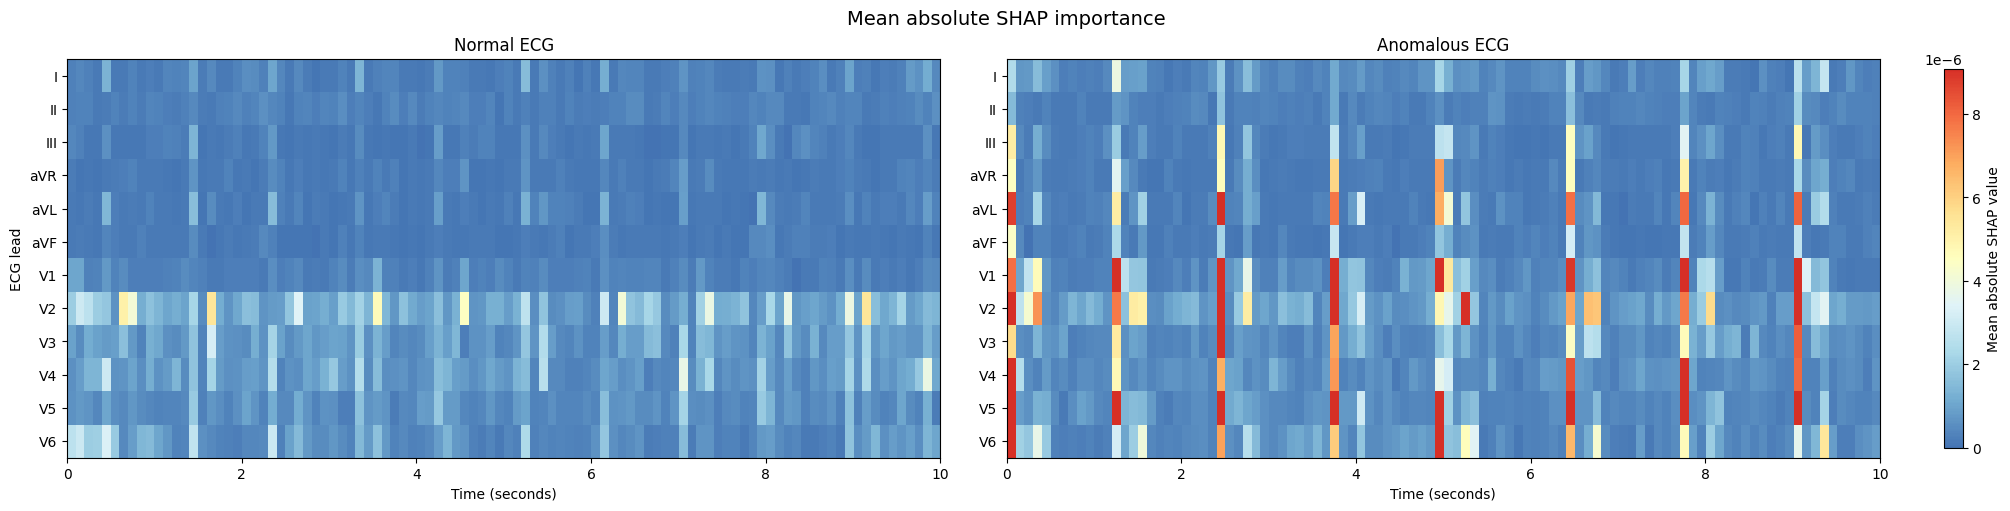

In [21]:
# Plot SHAP Heatmaps

plot_normal_anomalous_shap_heatmaps(
    normal_values=NormalSHAPIntervals,
    anomalous_values=AnomalousSHAPIntervals,
    interval_seconds=0.1,
    percentile=99.0,
    save_path=(
        SHAP_RESULTS_DIR
        / "tranad"
        / "shap_normal_vs_anomalous.png"
    ),
)

In [22]:
NormalTemporalSHAP = NormalSHAPIntervals.mean(axis=1)
AnomalousTemporalSHAP = AnomalousSHAPIntervals.mean(axis=1)

print(NormalTemporalSHAP.shape)
print(AnomalousTemporalSHAP.shape)

(100,)
(100,)


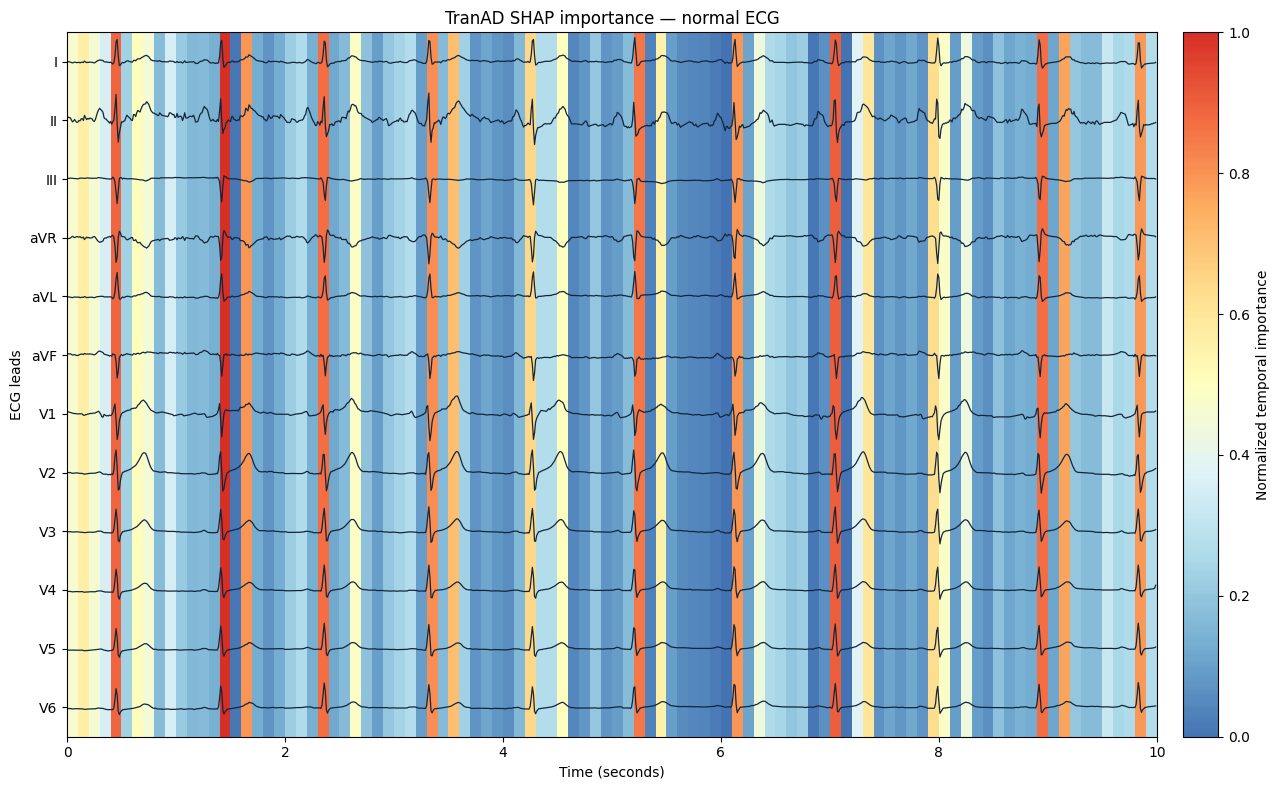

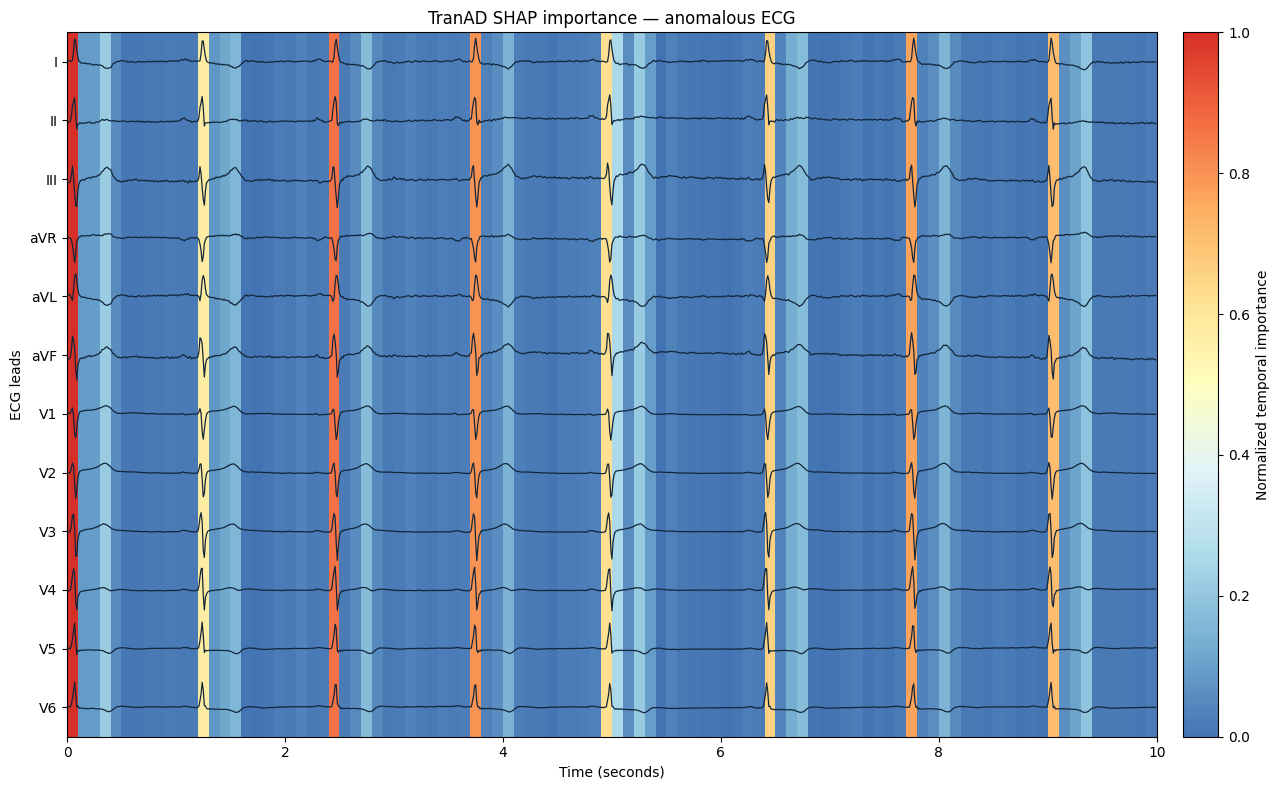

In [23]:
# Plot that is comparable with the Attention plot

plot_temporal_importance(
    values=NormalTemporalSHAP,
    title="TranAD SHAP importance — normal ECG",
    ecg=NormalECG.cpu().numpy(),
    save_path=(
        SHAP_RESULTS_DIR
        / "tranad"
        / "temporal_shap_normal.png"
    ),
)

plot_temporal_importance(
    values=AnomalousTemporalSHAP,
    title="TranAD SHAP importance — anomalous ECG",
    ecg=AnomalousECG.cpu().numpy(),
    save_path=(
        SHAP_RESULTS_DIR
        / "tranad"
        / "temporal_shap_anomalous.png"
    ),
)